Config filenames in this copy are the names on main.

# LoRA r24 + VPT ablation at 336

Run on an **A100 40 GB**. A–E share the existing LoRA r24 + extras recipe and prototype cosine head. Default screen: **1,000 classes, 40 fit + 5 holdout images/class, five epochs, seed 42**. Subset classes are remapped to 0..999; these accuracies are internal screening results, not comparable to the historical 79.9% CodaBench result.

| Arm | Prompts |
|---|---|
| A | None |
| B | Shallow, 8 tokens |
| C | Shallow, 16 tokens |
| D | Shallow, 32 tokens |
| E | Deep, 8 independent tokens per block |

Shallow prompts follow CLS and precede patches. Deep prompts replace prior prompt outputs at each block; sequence length does not grow across blocks. LoRA targets qkv/proj/fc1/fc2; norms, biases, positional embeddings and CLS also train in every arm. Prompt embeddings have no weight decay.

**Start here:** commit and push `qq_lora_vpt_ablation`, then open this notebook from that branch in Colab. The setup cell clones or pulls the branch into `/content/cs604_lora_vpt`; the data cell downloads the course dataset into `/content/data`. Experiment artifacts persist in Drive. Reruns skip only completed runs with matching settings, source hashes and artifacts. Interrupted arms restart from pretrained weights; optimizer resumption is not implemented.


In [1]:
REPO_URL = "https://github.com/keaidewoq/cs604-project.git"
BRANCH = "qq_lora_vpt_ablation"
REPO_DIR = "/content/cs604_lora_vpt"
DATA_DIR = "/content/data"
DRIVE_OUT = "/content/drive/MyDrive/CS604_RUNS"
EXPERIMENT_NAME = "qq_lora_vpt_336_c1000_seed42_v1"  # new name for changed settings

ARMS = ["A", "B", "E", "C", "D"]
CLASSES = 1000  # 10000 enables screening across all classes, still 40 fit + 5 holdout
HOLDOUT_PER_CLASS = 5
SPLIT_SEED = 42
SEEDS = [42]
EPOCHS = 5
BATCH_SIZE = 128
ACCUMULATION = 2  # effective batch 256; if reducing batch size, raise accumulation
WORKERS = 8
RUN_LR_PILOT = True
PILOT_EPOCHS = 3  # B at prompt LR 3e-4 and 1e-3; tie within 0.3 pp -> lower LR
PROMPT_LR = 1e-3  # used if RUN_LR_PILOT=False
RUN_SCREEN = True
RUN_CHECKS = True

# Optional stages: review the screen results before enabling these.
RUN_REPEATS = False
REPEAT_SEEDS = [42, 43, 44]
FINALIST_ARM = "B"  # set after reviewing results; also used for repeat comparisons
RUN_FINAL = False
FINAL_SEED = 42
FINAL_MINUTES = 144
RUN_PREDICT = False
RUN_LATENCY = False
TEAM = "08"
FINAL_CROP_PCT = 0.9  # standard single-view evaluation for a matched comparison
FINAL_FLIP = False


## 1. Clone or pull the experiment branch

After pushing `qq_lora_vpt_ablation`, run this cell to clone it into `/content/cs604_lora_vpt`, or pull it if already cloned. A hidden token authenticates the private repository without storing credentials in the remote URL. Course images are downloaded separately into `/content/data` in section 3.


In [2]:
import sys
from pathlib import Path
import base64
import os
import subprocess
from getpass import getpass

# Pass credentials through a temporary child-process environment, not the URL.
token = getpass("GitHub PAT (hidden; repo scope). Leave empty for a public repo: ")
git_env = os.environ.copy()
if token:
    auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
    git_env.update(GIT_CONFIG_COUNT="1", GIT_CONFIG_KEY_0="http.extraHeader",
                   GIT_CONFIG_VALUE_0=f"Authorization: Basic {auth}")
    del auth
try:
    if os.path.isdir(os.path.join(REPO_DIR, ".git")):
        subprocess.run(["git", "-C", REPO_DIR, "remote", "set-url", "origin", REPO_URL], check=True)
        subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin"], env=git_env, check=True)
        subprocess.run(["git", "-C", REPO_DIR, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only", "origin", BRANCH], env=git_env, check=True)
    else:
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, REPO_DIR], env=git_env, check=True)
finally:
    del token, git_env
os.chdir(REPO_DIR)
actual = subprocess.check_output(["git", "branch", "--show-current"], text=True).strip()
assert actual == BRANCH, f"Wrong branch: {actual}"
print("Branch:", actual)
print("Commit:", subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip())

assert Path("src/lora_r24_336px_vpt-prompt-length-sweep.py").is_file()
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
print("Working directory:", Path.cwd())


GitHub PAT (hidden; repo scope). Leave empty for a public repo: ··········
Branch: qq_lora_vpt_ablation
Commit: d93d1c9
Working directory: /content/cs604_lora_vpt


## 2. Install dependencies and run small CPU checks

Colab's installed CUDA PyTorch is retained when it satisfies the requirements. Checks cover shallow/deep prompt placement, gradients, partial checkpoint reload, LoRA merging, split separation and completed-run reuse. They use synthetic images, not the course data.

In [3]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt", "pytest"], check=True)
if RUN_CHECKS:
    check_env = os.environ.copy()
    check_env["CUDA_VISIBLE_DEVICES"] = ""
    subprocess.run([sys.executable, "-m", "pytest", "tests/test_lora_vpt.py", "-q"],
                   env=check_env, check=True)
import torch
import timm
assert torch.cuda.is_available(), "Select a GPU runtime before proceeding"
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "timm:", timm.__version__)

GPU: NVIDIA A100-SXM4-40GB
PyTorch: 2.11.0+cu130 timm: 1.0.30


## 3. Mount Drive and download data

If `CS604_RUNS` is a shared Drive folder, add a shortcut with that name under My Drive. Setup, prototype extraction and holdout evaluation are outside training-only time measurements.

In [4]:
from google.colab import drive

drive.mount("/content/drive")
if not Path(DRIVE_OUT).is_dir():
    raise FileNotFoundError(f"Add CS604_RUNS to My Drive, then verify {DRIVE_OUT}")
EXPERIMENT_DIR = Path(DRIVE_OUT) / EXPERIMENT_NAME
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

def run_live(command):
    process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, bufsize=1)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
        if returncode:
            raise subprocess.CalledProcessError(returncode, command)
    except BaseException:
        if process.poll() is None:
            process.terminate()
        process.wait()
        raise

run_live([sys.executable, "-u", "scripts/download_data.py", "--dest", DATA_DIR])
print("Experiment directory:", EXPERIMENT_DIR)

Mounted at /content/drive
[download] snapshot doem1997/cs604-course-data -> /content/data

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Fetching 7 files: 100%|██████████| 7/7 [02:01<00:00, 17.35s/it]
[download] extracting train.tar.gz
/content/cs604_lora_vpt/scripts/download_data.py:36: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(root)
[download] extracting val.tar.gz
[download] ready at /content/data
Experiment directory: /content/drive/MyDrive/CS604_RUNS/qq_lora_vpt_336_c1000_seed42_v1


## 4. Review all five architectures before training

The denominator is the original backbone at 336, excluding the classifier and added modules. The cap includes LoRA, extras and prompts. Batch size and accumulation stay fixed across arms. If you change these settings after starting an experiment, use a new `EXPERIMENT_NAME`.

In [5]:
import pandas as pd
from src.utils import load_config
from src.lora_r24_336px_vpt-prompt-length-sweep import ARMS as ARM_DEFINITIONS, arm_config, parameter_stats

base = load_config("configs/lora_r24_336px_vpt-prompt-length-sweep.yaml")
base.num_classes = CLASSES
counts = []
for arm in ARMS:
    assert arm in ARM_DEFINITIONS
    cfg = arm_config(base, arm, SEEDS[0], PROMPT_LR)
    stats = parameter_stats(cfg)
    assert stats["adaptation_pct"] < 5
    counts.append({"arm": arm, "mode": cfg.prompt_mode,
                   "tokens": cfg.prompt_length, **stats})
display(pd.DataFrame(counts))
(EXPERIMENT_DIR / "parameter_counts.json").write_text(pd.DataFrame(counts).to_json(orient="records", indent=2))

[lora] wrapped 48 layers (qkv, proj, fc1, fc2 in 12 blocks), rank=24, alpha=24.0, dropout=0.0: 3,538,944 params
[unfreeze_extra] norm, bias, pos_embed, cls_token: 462,336 params
[params] backbone trainable 4.00M/85.99M (4.65%, head excluded)
[lora] wrapped 48 layers (qkv, proj, fc1, fc2 in 12 blocks), rank=24, alpha=24.0, dropout=0.0: 3,538,944 params
[unfreeze_extra] norm, bias, pos_embed, cls_token: 462,336 params
[params] backbone trainable 4.01M/85.99M (4.66%, head excluded)
[lora] wrapped 48 layers (qkv, proj, fc1, fc2 in 12 blocks), rank=24, alpha=24.0, dropout=0.0: 3,538,944 params
[unfreeze_extra] norm, bias, pos_embed, cls_token: 462,336 params
[params] backbone trainable 4.08M/85.99M (4.74%, head excluded)
[lora] wrapped 48 layers (qkv, proj, fc1, fc2 in 12 blocks), rank=24, alpha=24.0, dropout=0.0: 3,538,944 params
[unfreeze_extra] norm, bias, pos_embed, cls_token: 462,336 params
[params] backbone trainable 4.01M/85.99M (4.67%, head excluded)
[lora] wrapped 48 layers (qkv, p

,arm,mode,tokens,adaptation_parameters,original_backbone_parameters,adaptation_pct,prompt_parameters
0,A,none,0,4001280,85986816,4.653365,0
1,B,shallow,8,4007424,85986816,4.660510,6144
2,E,deep,8,4075008,85986816,4.739108,73728
3,C,shallow,16,4013568,85986816,4.667655,12288
4,D,shallow,32,4025856,85986816,4.681946,24576


1038

## 5. Run the prompt-LR pilot and A–E screen

Each arm starts from pretrained weights and the same fitting-only prototypes. The pilot uses B for three epochs at two prompt learning rates; within 0.3 percentage points of the best score, choose the lower rate. Screening then restarts B for five epochs, like every other arm.

The runner saves `split/` manifests and original-to-local class mapping, prototype provenance, resolved configs, checkpoints, logs, parameter statistics and a comparison CSV. It validates hashes before skipping completed runs. Reusing the holdout for pilot and architecture selection makes these development scores; seed repeats and final CodaBench evaluation provide additional evidence.

In [6]:
def screen_command(seeds, arms, comparison_stem="comparison", lr_pilot=False, prompt_lr=PROMPT_LR):
    command = [sys.executable, "-u", "-m", "src.lora_r24_336px_vpt-prompt-length-sweep", "screen",
               "--data-root", DATA_DIR, "--output-dir", str(EXPERIMENT_DIR),
               "--classes", str(CLASSES), "--holdout", str(HOLDOUT_PER_CLASS),
               "--split-seed", str(SPLIT_SEED), "--epochs", str(EPOCHS),
               "--batch-size", str(BATCH_SIZE), "--accum", str(ACCUMULATION),
               "--workers", str(WORKERS), "--prompt-lr", str(prompt_lr),
               "--pilot-epochs", str(PILOT_EPOCHS), "--comparison-stem", comparison_stem,
               "--seeds", *map(str, seeds), "--arms", *arms]
    if lr_pilot:
        command.append("--lr-pilot")
    return command

if RUN_SCREEN:
    run_live(screen_command(SEEDS, ARMS, lr_pilot=RUN_LR_PILOT))

Streaming output truncated to the last 5000 lines.
epoch 3/5: 100%|██████████| 312/312 [01:57<00:00,  2.66it/s, loss=1.5540, lr=1.13e-04]
[epoch 3] train_loss=1.5276 val_loss=1.5315 val_acc=0.8976
[epoch 3] new best val_acc=0.8976

epoch 4/5: 100%|██████████| 312/312 [01:57<00:00,  2.66it/s, loss=1.5126, lr=3.16e-05]
[epoch 4] train_loss=1.4427 val_loss=1.5197 val_acc=0.9044
[epoch 4] new best val_acc=0.9044

epoch 5/5: 100%|██████████| 312/312 [01:56<00:00,  2.68it/s, loss=1.3459, lr=0.00e+00]
[epoch 5] train_loss=1.4166 val_loss=1.5219 val_acc=0.9044
[end] trainable=4.78M/90.31M (5.29%) wall_s=633.7 gpu_hours=0.1760 peak_vram_gb=20.122
[train] done. checkpoints in /content/drive/.shortcut-targets-by-id/107nc4GKekmaKe38GR_8VBn3Bh_xH-ZtR/CS604_RUNS/qq_lora_vpt_336_c1000_seed42_v1/screen/C_seed42/lora_20261016_030823
[lora] wrapped 48 layers (qkv, proj, fc1, fc2 in 12 blocks), rank=24, alpha=24.0, dropout=0.0: 3,538,944 params
[unfreeze_extra] norm, bias, pos_embed, cls_token: 462,336 p

## 6. Compare accuracy, resource use and learning curves

`delta_vs_A_pp` compares arms with A from the same seed. `adaptation_pct` excludes the classifier; `wall_gpu_hours` includes run setup and validation. Training throughput uses processed images divided by training-only seconds. GPU VRAM is peak allocated GiB, not total device usage.

,arm,seed,best_val_acc,final_val_acc,delta_vs_A_pp,best_epoch,adaptation_pct,prompt_parameters,peak_vram_GiB,training_minutes,wall_gpu_hours,training_images_per_second
2,E,42,0.9072,0.9072,0.40,5,4.739108,73728,19.969160,10.025000,0.180198,331.970075
4,D,42,0.9058,0.9058,0.26,5,4.681946,24576,20.780382,10.073667,0.180802,330.366302
3,C,42,0.9044,0.9044,0.12,4,4.667655,12288,20.122339,9.767333,0.176028,340.727595
1,B,42,0.9040,0.9040,0.08,5,4.660510,6144,19.802137,9.656333,0.173847,344.644275
0,A,42,0.9032,0.9032,0.00,5,4.653365,0,19.285697,9.511500,0.171357,349.892236


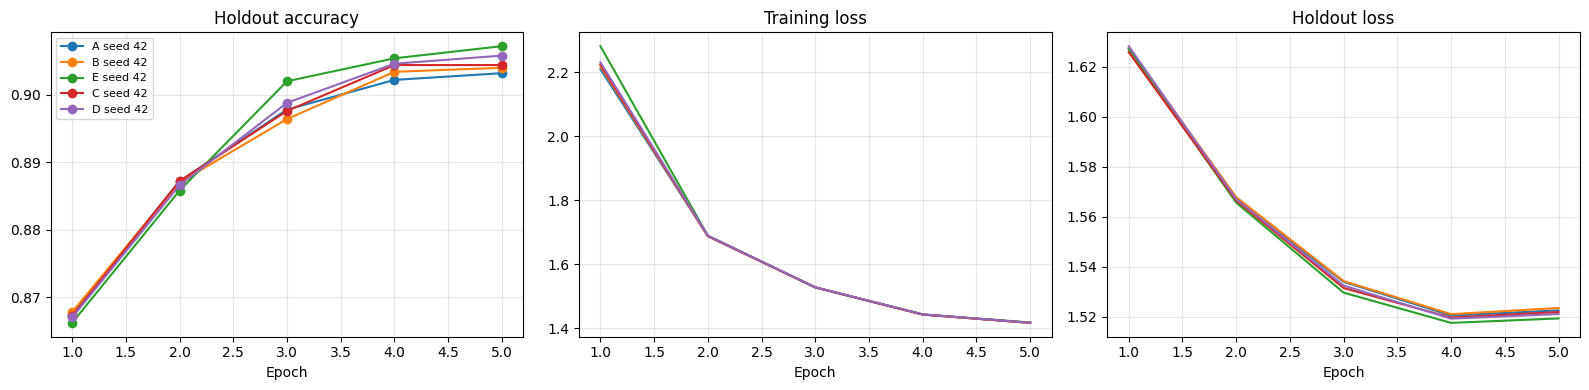

Selected prompt LR: 0.0003


In [7]:
import json
import matplotlib.pyplot as plt

comparison_path = EXPERIMENT_DIR / "comparison.csv"
if comparison_path.is_file():
    results = pd.read_csv(comparison_path)
    columns = ["arm", "seed", "best_val_acc", "final_val_acc", "delta_vs_A_pp",
               "best_epoch", "adaptation_pct", "prompt_parameters", "peak_vram_GiB",
               "training_minutes", "wall_gpu_hours", "training_images_per_second"]
    display(results[columns].sort_values(["seed", "best_val_acc"], ascending=[True, False]))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for row in results.to_dict("records"):
        history = pd.read_csv(Path(row["run_dir"]) / "epoch_log.csv")
        label = f"{row['arm']} seed {row['seed']}"
        axes[0].plot(history.epoch, history.val_acc, marker="o", label=label)
        axes[1].plot(history.epoch, history.train_loss, label=label)
        axes[2].plot(history.epoch, history.val_loss, label=label)
    for ax, title in zip(axes, ["Holdout accuracy", "Training loss", "Holdout loss"]):
        ax.set(xlabel="Epoch", title=title)
        ax.grid(alpha=.3)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(EXPERIMENT_DIR / "comparison_curves.png", dpi=160)
    plt.show()
else:
    print("No comparison yet; complete at least one screen arm")

def selected_prompt_lr():
    selection = EXPERIMENT_DIR / "prompt_lr_selection.json"
    return json.loads(selection.read_text())["selected"] if selection.is_file() else PROMPT_LR
print("Selected prompt LR:", selected_prompt_lr())

## 7. Optional: repeat A and the selected hybrid with more seeds

Set `FINALIST_ARM` and enable `RUN_REPEATS` above after reviewing the screen. Keep the split and prompt LR fixed. Results go to `comparison_repeats.csv`; the original A–E comparison remains available. Seed 42 runs are reused when their settings match.

In [ ]:
if RUN_REPEATS:
    assert FINALIST_ARM in ARM_DEFINITIONS and FINALIST_ARM != "A"
    run_live(screen_command(REPEAT_SEEDS, ["A", FINALIST_ARM],
                            comparison_stem="comparison_repeats", prompt_lr=selected_prompt_lr()))
    repeats = pd.read_csv(EXPERIMENT_DIR / "comparison_repeats.csv")
    display(repeats[["arm", "seed", "best_val_acc", "delta_vs_A_pp"]])
    display(repeats.groupby("arm").best_val_acc.agg(["mean", "std", "count"]))

## 8. Optional: fresh all-data finalist, 144 training minutes

Enable `RUN_FINAL` and set `FINALIST_ARM`. This uses all 450,000 images, original class IDs, newly built all-data prototypes and fresh pretrained weights. It never loads a screening checkpoint. The schedule is 5% time warmup then cosine, without an epoch ceiling. Choose A as the finalist to run a matched all-data baseline in its own folder.

This stage does not run by default. Final artifacts are under `final_<arm>_seed<seed>/`.

In [ ]:
FINAL_DIR = EXPERIMENT_DIR / f"final_{FINALIST_ARM}_seed{FINAL_SEED}"
if RUN_FINAL:
    run_live([sys.executable, "-u", "-m", "src.lora_r24_336px_vpt-prompt-length-sweep", "final",
              "--data-root", DATA_DIR, "--output-dir", str(FINAL_DIR),
              "--arm", FINALIST_ARM, "--seed", str(FINAL_SEED),
              "--prompt-lr", str(selected_prompt_lr()), "--minutes", str(FINAL_MINUTES),
              "--batch-size", str(BATCH_SIZE), "--accum", str(ACCUMULATION),
              "--workers", str(WORKERS)])
if (FINAL_DIR / "final_result.json").is_file():
    final_result = json.loads((FINAL_DIR / "final_result.json").read_text())
    FINAL_RUN = Path(final_result["run_dir"])
    print("Final run:", FINAL_RUN)

## 9. Optional: predictions and submission ZIP

Use the final run's saved config and `last.pt`. Default evaluation is crop 0.9, no flip; use identical inference settings for a fair A/hybrid comparison. Changing to crop 0.75 + flip is a separate inference experiment. The existing repository does not include Van's zoom implementation, so this notebook does not reproduce the historical 79.9% zoom score.

In [ ]:
import shutil
if RUN_PREDICT:
    assert "FINAL_RUN" in globals(), "Complete or select a final run first"
    tag = f"crop{FINAL_CROP_PCT:.2f}_flip{int(FINAL_FLIP)}"
    prediction_dir = FINAL_RUN / tag
    for split in ["val", "test"]:
        if not (Path(DATA_DIR) / f"{split}.txt").is_file():
            continue
        command = [sys.executable, "-u", "-m", "src.predict",
                   "--config", str(FINAL_RUN / "config.yaml"),
                   "--ckpt", str(FINAL_RUN / "last.pt"), "--split", split,
                   "--team", TEAM, "--data_root", DATA_DIR,
                   "--out_dir", str(prediction_dir), "--crop_pct", str(FINAL_CROP_PCT)]
        if FINAL_FLIP:
            command.append("--tta_flip")
        run_live(command)
        name = f"{split}_team_{TEAM}"
        archive = shutil.make_archive(str(prediction_dir / name), "zip",
                                      root_dir=prediction_dir, base_dir=f"{name}.txt")
        print("Submission:", archive)

## 10. Optional: merged-LoRA inference latency

Merge LoRA after loading the trained checkpoint; prompt tokens remain active. Measure synthetic single-view forwards in BF16, batches 1 and 64, 30 warmups and 200 iterations. This excludes preprocessing, transfers and flip/zoom TTA. Results are saved in the final run folder. All reported latency comparisons should use the same GPU and measurement settings.

In [ ]:
if RUN_LATENCY:
    from src.model import build_model
    from src.predict import load_checkpoint
    from src.peft.lora import merge_lora
    from scripts.benchmark_latency import measure
    from src.utils import set_seed
    assert "FINAL_RUN" in globals(), "Complete or select a final run first"
    cfg = load_config(FINAL_RUN / "config.yaml")
    cfg.pretrained = True  # restore frozen backbone for the partial checkpoint
    set_seed(int(cfg.seed))
    device = torch.device("cuda")
    model = build_model(cfg).to(device).eval()
    load_checkpoint(model, FINAL_RUN / "last.pt", device)
    sample = torch.randn(1, 3, cfg.img_size, cfg.img_size, device=device)
    with torch.no_grad():
        before = model(sample).float()
        merge_lora(model)
        after = model(sample).float()
    max_difference = (before - after).abs().max().item()
    torch.testing.assert_close(before, after, atol=2e-4, rtol=2e-4)
    timings = {"gpu": torch.cuda.get_device_name(0), "torch": str(torch.__version__),
               "checkpoint": str(FINAL_RUN / "last.pt"), "merged_lora": True,
               "prompt_mode": cfg.prompt_mode, "prompt_length": cfg.prompt_length,
               "precision": "bf16", "warmups": 30, "iterations": 200,
               "single_view": True, "merge_fp32_max_logit_difference": max_difference}
    for batch_size in [1, 64]:
        sample = torch.randn(batch_size, 3, cfg.img_size, cfg.img_size, device=device)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
            ms, _ = measure(model, sample, device, 30, 200)
        timings[f"batch{batch_size}_ms_per_image"] = ms
    (FINAL_RUN / "inference_latency_merged.json").write_text(json.dumps(timings, indent=2))
    print(timings)
    del model, sample
    torch.cuda.empty_cache()

## Finish

Download or share `comparison.csv`, `comparison_curves.png` and optional repeat/final artifacts from the experiment folder. Add actual results to `report/progress_log.md` after reviewing them; add official CodaBench scores to `report/experiment_index.csv` after submission. Disconnect the runtime manually when finished.